# 4ª Entrega: Clustering (aprendizaje no supervisado)
## Producción de pozos de gas y petróleo no convencional (Argentina)

**Curso:** EnergIA Digital - Data Science (Fundación YPF)
##### Alumnos: Lucia Chacon,Clara Gimenez,Valeria villarpando,Rogelio Zandoval

### Objetivo
Agrupar los pozos según su perfil (profundidad, año de inicio y producción de los primeros 12 meses) para ver **qué tipos de pozos existen**, sin decirle al modelo de antemano de qué tipo es cada uno.

### Algoritmo elegido: K-Means
- Es simple, rápido y fácil de interpretar: cada grupo tiene un "centro" que describe al pozo típico.
- Se compara después con otros dos algoritmos (jerárquico aglomerativo y mezcla gaussiana) para justificar la elección.

### Criterios de decisión (definidos antes de ver los resultados)
1. **Cantidad de grupos (k):** se elige el k con mayor *silhouette* entre los que no tienen ningún grupo con menos del 3% de los pozos. Si dos valores de k difieren en menos de 0,01, se elige el más chico (parsimonia).
2. **Variables:** se parte de todas y se prueba si quitar las coordenadas mejora la separación de los grupos.
3. **Estabilidad:** el resultado tiene que repetirse con distintas semillas aleatorias.
4. **Interpretabilidad:** los grupos tienen que poder describirse en palabras.
5. **Validación externa:** al final se compara con el tipo de pozo (gasífero, petrolífero...) que **no** se usó para agrupar.

### Etapas
AED y preparación de variables, modelo base, mejora, comparación de algoritmos, estabilidad, perfil de los grupos, validación y conclusiones.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (9, 5)
SEED = 42

## 1. Preparación de datos: una fila por pozo

In [7]:
RUTA = '/content/produccin-de-pozos-de-gas-y-petrleo-no-convencional.csv'

cols = ['idpozo', 'anio', 'prod_pet', 'prod_gas', 'prod_agua', 'provincia', 'formacion', 'tipopozo',
        'profundidad', 'coordenadax', 'coordenaday', 'fecha_data']
df = pd.read_csv(RUTA, usecols=cols)
df['tipopozo'] = df['tipopozo'].replace('Sin dato', np.nan)

df['fecha'] = pd.to_datetime(df['fecha_data'])
for c in ['prod_pet', 'prod_gas', 'prod_agua']:
    df[c] = df[c].clip(lower=0)                        # negativos -> 0
df = df.sort_values(['idpozo', 'fecha'])
df['mes_n'] = df.groupby('idpozo').cumcount() + 1       # meses desde el primer registro

pozos = df.groupby('idpozo').agg(
    tipopozo=('tipopozo', 'first'), provincia=('provincia', 'first'), formacion=('formacion', 'first'),
    profundidad=('profundidad', 'first'), x=('coordenadax', 'first'), y=('coordenaday', 'first'),
    anio_inicio=('anio', 'first'), meses=('mes_n', 'max'))
prim12 = df[df['mes_n'] <= 12].groupby('idpozo')[['prod_pet', 'prod_gas', 'prod_agua']].sum()
prim12.columns = ['pet_12m', 'gas_12m', 'agua_12m']
pozos = pozos.join(prim12)

# Profundidad: 0 y valores imposibles (> 10.000 m) se tratan como faltantes
pozos['profundidad'] = pozos['profundidad'].where(pozos['profundidad'].between(1, 10000))

# Solo pozos con al menos 12 meses de historia (para tener la producción de un año completo)
datos = pozos[pozos['meses'] >= 12].copy()
print('Pozos totales:', len(pozos), '| con 12 meses o más:', len(datos))
datos['tipopozo'].value_counts(dropna=False)

Pozos totales: 2742 | con 12 meses o más: 2511


,count
tipopozo,
Petrolífero,1208
Gasífero,848
Otro tipo,443
Sumidero,10
Inyección de Agua,2


**Decisión:** a diferencia de la clasificación, acá se usan **todos los tipos de pozo** (no solo petrolíferos). Como el clustering no tiene una "respuesta correcta", conviene que el algoritmo descubra solo si hay grupos de gas, de petróleo y otros. El tipo de pozo se usa recién al final, para validar.

## 2. Análisis exploratorio de las variables a agrupar

In [8]:
feats_prod = ['pet_12m', 'gas_12m', 'agua_12m']
feats_pozo = ['profundidad', 'anio_inicio']
feats_geo = ['x', 'y']
datos[feats_pozo + feats_geo + feats_prod].describe().T

,count,mean,std,min,25%,50%,75%,max
profundidad,2444.0,4253.403196,1405.342726,301.000000,3073.000000,3975.000000,5472.250000,7828.00000
anio_inicio,2511.0,2017.896456,4.737453,2006.000000,2015.000000,2017.000000,2022.000000,2025.00000
x,2511.0,-68.745637,0.391156,-69.903384,-68.921437,-68.716653,-68.604947,-67.67916
y,2511.0,-38.446676,0.383999,-46.403821,-38.709928,-38.351078,-38.295129,-36.20600
pet_12m,2511.0,14444.704260,17908.308257,0.000000,78.545000,4083.770000,28160.390000,92387.49000
gas_12m,2511.0,11690.167907,18834.378671,0.000000,2092.130000,4690.290000,11408.545000,140314.49000
agua_12m,2511.0,6671.118869,7637.717457,0.000000,1202.240000,4060.610000,9552.510000,52947.19000


Nulos:
profundidad    67
dtype: int64


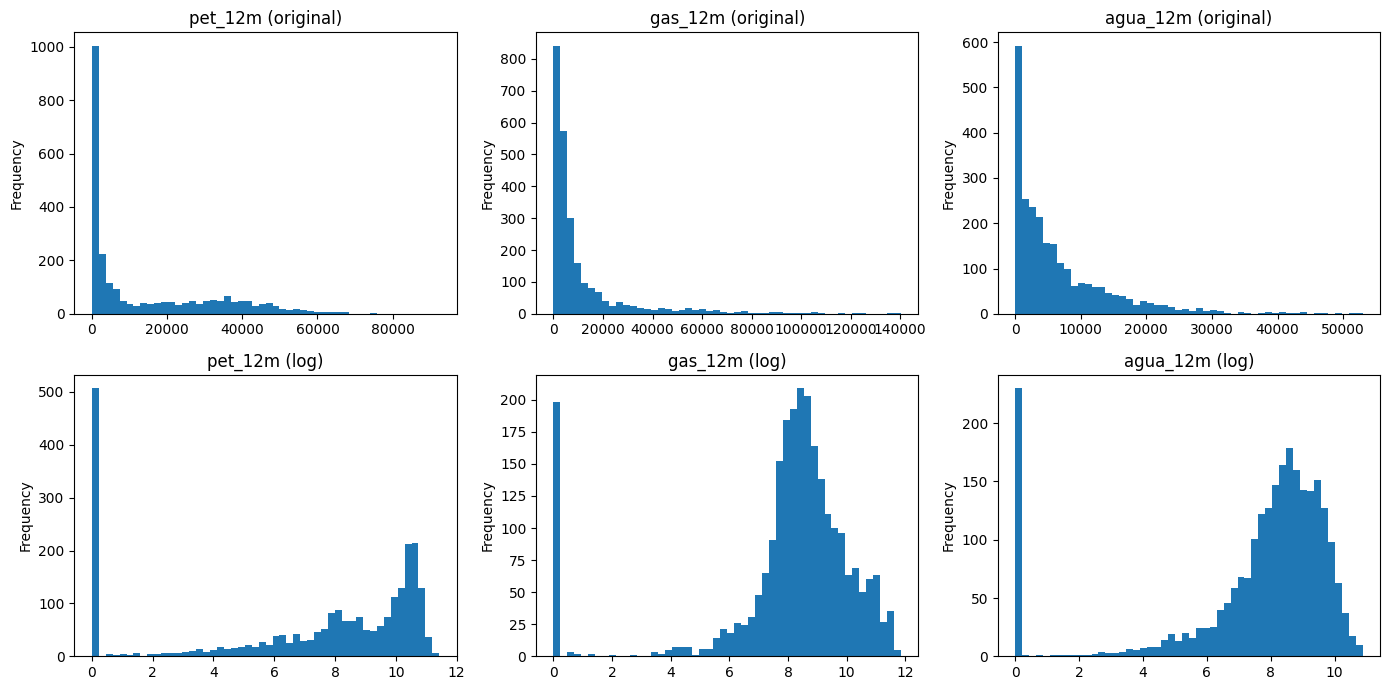

In [9]:
print('Nulos:'); print(datos[feats_pozo + feats_geo + feats_prod].isna().sum()[lambda s: s > 0])
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax[0], feats_prod):
    datos[c].plot.hist(bins=50, ax=a, title=f'{c} (original)')
for a, c in zip(ax[1], feats_prod):
    np.log1p(datos[c]).plot.hist(bins=50, ax=a, title=f'{c} (log)')
plt.tight_layout(); plt.show()

**Decisión:** la producción tiene una cola muy larga (muchos pozos con poca producción y unos pocos con muchísima). K-Means usa distancias, y esos pocos pozos dominarían el resultado. Por eso se aplica **logaritmo** a las tres variables de producción (`log1p`), que acerca la distribución a una forma más simétrica.

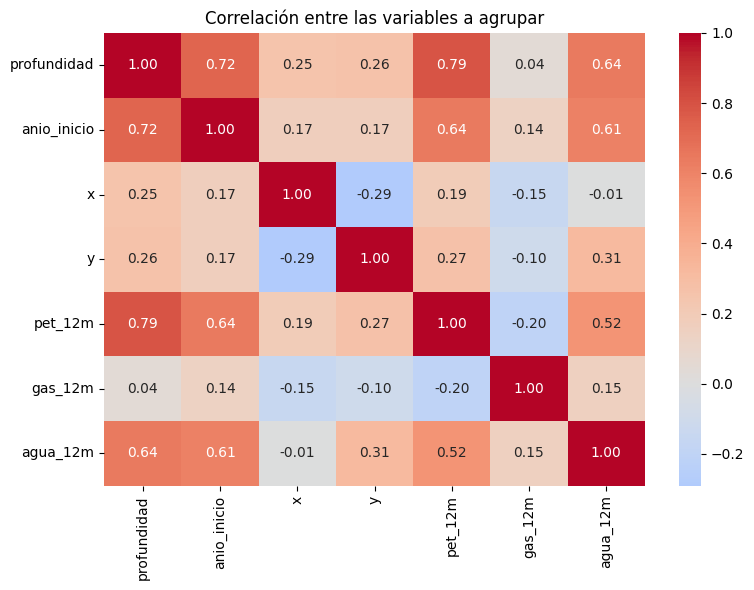

In [10]:
cols_corr = feats_pozo + feats_geo + feats_prod
plt.figure(figsize=(8, 6))
sns.heatmap(datos[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlación entre las variables a agrupar'); plt.tight_layout(); plt.show()

## 3. Preparación de las variables
- Producción: `log1p` (explicado arriba).
- Faltantes: se imputan con la mediana (solo la profundidad tiene).
- **Escalado con `StandardScaler`:** es obligatorio en K-Means; si no, las variables con números grandes (como la profundidad en metros) pesarían más que las demás.

In [11]:
def preparar(columnas):
    X = datos[columnas].copy()
    for c in feats_prod:
        if c in X.columns:
            X[c] = np.log1p(X[c])
    X = SimpleImputer(strategy='median').fit_transform(X)
    return StandardScaler().fit_transform(X)

def evaluar(Xs, ks=range(2, 9)):
    filas = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=SEED).fit(Xs)
        filas.append({'k': k, 'inercia': km.inertia_,
                      'silhouette': silhouette_score(Xs, km.labels_),
                      'davies_bouldin': davies_bouldin_score(Xs, km.labels_),
                      'grupo_mas_chico_%': np.bincount(km.labels_).min() / len(Xs) * 100})
    return pd.DataFrame(filas).set_index('k').round(3)

def elegir_k(tab, min_pct=3, tol=0.01):
    # Criterio 1: mayor silhouette entre los k sin grupos diminutos; ante empate (< tol), el k más chico
    ok = tab[tab['grupo_mas_chico_%'] >= min_pct]
    mejor = ok['silhouette'].max()
    return int(ok[ok['silhouette'] >= mejor - tol].index.min())

## 4. Modelo base: K-Means con todas las variables

In [12]:
feats_v1 = feats_pozo + feats_geo + feats_prod
X1 = preparar(feats_v1)
tab1 = evaluar(X1)
tab1

,inercia,silhouette,davies_bouldin,grupo_mas_chico_%
k,,,,
2,11962.021,0.338,1.283,45.360
3,8716.187,0.372,1.114,9.638
4,6585.502,0.436,0.918,9.080
5,5578.576,0.407,0.975,8.841
6,5045.889,0.423,1.030,8.403
7,4201.023,0.442,0.840,0.080
8,3896.739,0.365,0.947,0.080


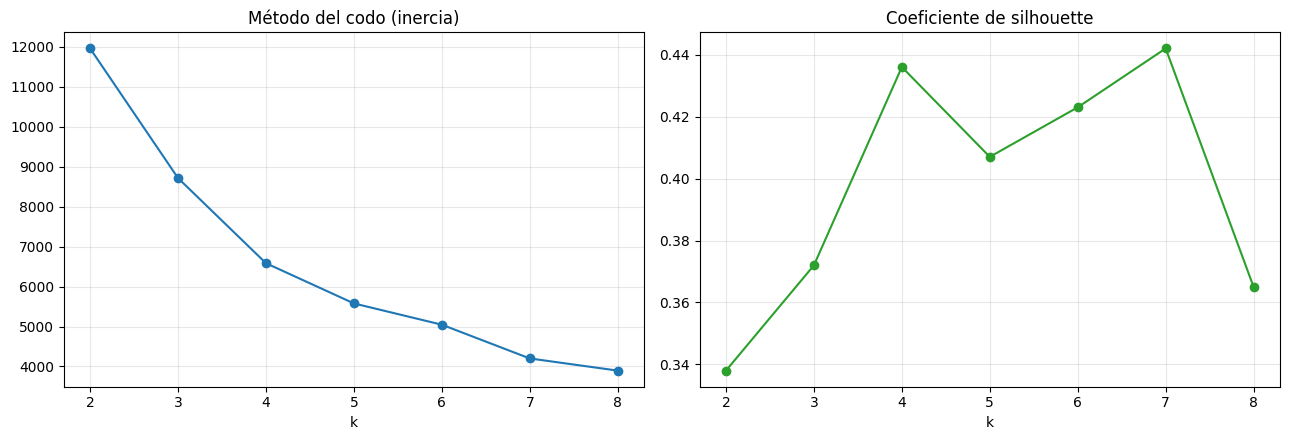

k elegido para el modelo base: 4 | silhouette = 0.436


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
tab1['inercia'].plot(marker='o', ax=ax[0], title='Método del codo (inercia)'); ax[0].set_xlabel('k'); ax[0].grid(alpha=.3)
tab1['silhouette'].plot(marker='o', ax=ax[1], title='Coeficiente de silhouette', color='tab:green'); ax[1].set_xlabel('k'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
k1 = elegir_k(tab1)
print('k elegido para el modelo base:', k1, '| silhouette =', tab1.loc[k1, 'silhouette'])

**Cómo se lee:** la inercia siempre baja al aumentar k, así que se busca el "codo" donde deja de mejorar mucho. El silhouette mide qué tan separados quedan los grupos (de -1 a 1; más alto es mejor). Los k con un grupo de menos del 3% de los pozos se descartan, porque suelen ser pozos atípicos aislados.

## 5. Mejora: ¿ayudan las coordenadas?
Las coordenadas (x, y) describen dónde está el pozo, no cómo produce. Se prueba agrupar solo con profundidad, año de inicio y producción, y se compara con el modelo base.

In [14]:
feats_v2 = feats_pozo + feats_prod
X2 = preparar(feats_v2)
tab2 = evaluar(X2)
k2 = elegir_k(tab2)
display(tab2)
comp = pd.DataFrame({
    'variables': ['Todas (con coordenadas)', 'Sin coordenadas'],
    'k elegido': [k1, k2],
    'silhouette': [tab1.loc[k1, 'silhouette'], tab2.loc[k2, 'silhouette']],
    'davies_bouldin': [tab1.loc[k1, 'davies_bouldin'], tab2.loc[k2, 'davies_bouldin']]}).set_index('variables')
comp

,inercia,silhouette,davies_bouldin,grupo_mas_chico_%
k,,,,
2,7339.689,0.391,1.042,47.431
3,4045.295,0.450,0.822,9.558
4,3180.074,0.444,0.895,9.438
5,2748.422,0.366,0.997,9.200
6,2346.155,0.373,0.980,4.659
7,2112.796,0.368,1.035,3.425
8,1878.486,0.384,0.949,3.146


,k elegido,silhouette,davies_bouldin
variables,,,
Todas (con coordenadas),4,0.436,0.918
Sin coordenadas,3,0.450,0.822


In [15]:
# Decisión por criterio: se queda con la versión de mayor silhouette
usar_v2 = comp['silhouette'].iloc[1] >= comp['silhouette'].iloc[0]
feats_final, Xf, k_final = (feats_v2, X2, k2) if usar_v2 else (feats_v1, X1, k1)
print('Variables elegidas:', feats_final)
print('k final:', k_final)

Variables elegidas: ['profundidad', 'anio_inicio', 'pet_12m', 'gas_12m', 'agua_12m']
k final: 3


## 6. Comparación de algoritmos (con el k elegido)

In [16]:
modelos = {
    'K-Means': KMeans(k_final, n_init=10, random_state=SEED),
    'Jerárquico (Ward)': AgglomerativeClustering(k_final),
    'Mezcla gaussiana': GaussianMixture(k_final, random_state=SEED),
}
filas = []
for nombre, m in modelos.items():
    etiquetas = m.fit_predict(Xf)
    filas.append({'algoritmo': nombre, 'silhouette': silhouette_score(Xf, etiquetas),
                  'davies_bouldin': davies_bouldin_score(Xf, etiquetas),
                  'grupo_mas_chico_%': np.bincount(etiquetas).min() / len(Xf) * 100})
pd.DataFrame(filas).set_index('algoritmo').round(3)

,silhouette,davies_bouldin,grupo_mas_chico_%
algoritmo,,,
K-Means,0.450,0.822,9.558
Jerárquico (Ward),0.437,0.790,8.005
Mezcla gaussiana,0.306,1.136,8.523


**Decisión:** se mantiene K-Means si tiene el silhouette más alto o equivalente, porque además es el más fácil de explicar y de aplicar a pozos nuevos (basta calcular la distancia a cada centro). Si otro algoritmo lo supera claramente, habría que reconsiderar la elección.

## 7. Estabilidad del resultado

In [17]:
base = KMeans(k_final, n_init=10, random_state=SEED).fit(Xf).labels_
aris = []
for s in range(10):
    otro = KMeans(k_final, n_init=1, random_state=s).fit(Xf).labels_
    aris.append(adjusted_rand_score(base, otro))
print('Adjusted Rand Index promedio entre corridas:', round(np.mean(aris), 3), '(1 = agrupación idéntica)')
print('Mínimo:', round(np.min(aris), 3))

Adjusted Rand Index promedio entre corridas: 0.998 (1 = agrupación idéntica)
Mínimo: 0.992


## 8. Modelo final y visualización

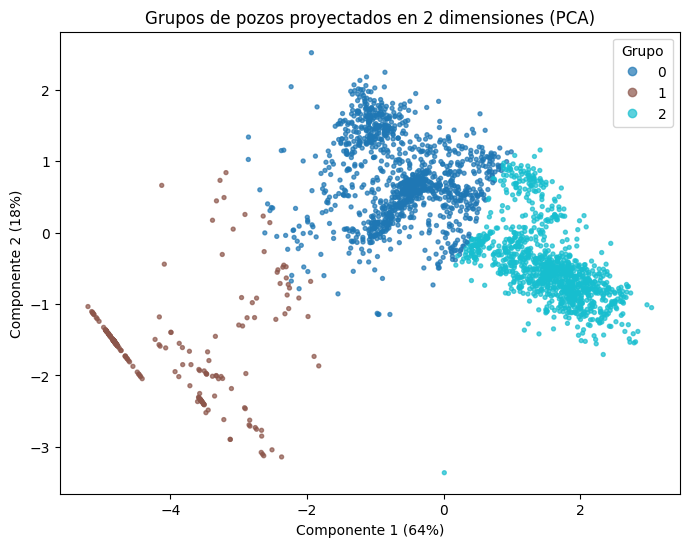

In [18]:
km_final = KMeans(k_final, n_init=10, random_state=SEED).fit(Xf)
datos['grupo'] = km_final.labels_

pca = PCA(2, random_state=SEED).fit(Xf)
P = pca.transform(Xf)
plt.figure(figsize=(8, 6))
sc = plt.scatter(P[:, 0], P[:, 1], c=datos['grupo'], cmap='tab10', s=8, alpha=.7)
plt.legend(*sc.legend_elements(), title='Grupo')
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]:.0%})'); plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title('Grupos de pozos proyectados en 2 dimensiones (PCA)'); plt.show()

## 9. Perfil de cada grupo

In [19]:
perfil = datos.groupby('grupo').agg(
    pozos=('grupo', 'size'),
    profundidad_mediana=('profundidad', 'median'),
    anio_inicio_mediano=('anio_inicio', 'median'),
    pet_12m_mediana=('pet_12m', 'median'),
    gas_12m_mediana=('gas_12m', 'median'),
    agua_12m_mediana=('agua_12m', 'median'))
perfil['% del total'] = (perfil['pozos'] / len(datos) * 100).round(1)
perfil.round(0)

,pozos,profundidad_mediana,anio_inicio_mediano,pet_12m_mediana,gas_12m_mediana,agua_12m_mediana,% del total
grupo,,,,,,,
0,1179,3116.0,2015.0,805.0,6379.0,2155.0,47.0
1,240,3098.0,2006.0,0.0,0.0,0.0,10.0
2,1092,5622.0,2023.0,31509.0,5059.0,9805.0,44.0


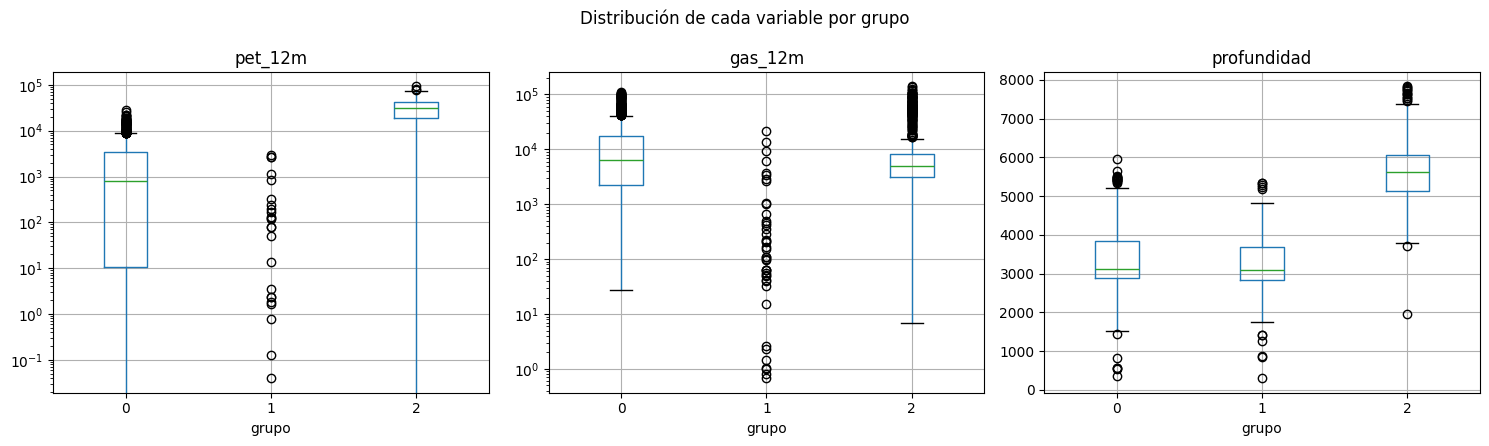

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, c in zip(ax, ['pet_12m', 'gas_12m', 'profundidad']):
    datos.boxplot(column=c, by='grupo', ax=a)
    a.set_title(c); a.set_xlabel('grupo'); a.set_yscale('log' if c != 'profundidad' else 'linear')
plt.suptitle('Distribución de cada variable por grupo'); plt.tight_layout(); plt.show()

In [21]:
print('Tipo de pozo por grupo (% de cada grupo):')
display((pd.crosstab(datos['grupo'], datos['tipopozo'].fillna('Sin dato'), normalize='index') * 100).round(1))
print('\nFormación más frecuente por grupo:')
display(datos.groupby('grupo')['formacion'].agg(lambda s: s.value_counts().head(2).to_dict()))
print('Provincia (% de cada grupo):')
(pd.crosstab(datos['grupo'], datos['provincia'], normalize='index') * 100).round(1)

Tipo de pozo por grupo (% de cada grupo):


tipopozo,Gasífero,Inyección de Agua,Otro tipo,Petrolífero,Sumidero
grupo,,,,,
0,56.1,0.0,22.8,21.0,0.0
1,25.4,0.8,65.0,4.6,4.2
2,11.4,0.0,1.6,86.9,0.0



Formación más frecuente por grupo:


,formacion
grupo,
0,"{'vaca muerta': 517, 'lajas': 383}"
1,"{'vaca muerta': 113, 'lajas': 51}"
2,"{'vaca muerta': 1038, 'punta rosada': 50}"


Provincia (% de cada grupo):


provincia,Chubut,Mendoza,Neuquén,Rio Negro,Santa Cruz
grupo,,,,,
0,0.1,0.3,83.7,15.8,0.1
1,0.0,0.4,93.3,6.2,0.0
2,0.0,0.2,99.5,0.4,0.0


## 10. Validación externa

In [22]:
# El tipo de pozo NO se usó para agrupar: sirve para ver si los grupos tienen sentido
tipo = datos['tipopozo'].fillna('Sin dato')
print('Adjusted Rand Index (grupos vs tipo de pozo):', round(adjusted_rand_score(tipo, datos['grupo']), 3))
print('(0 = sin relación, 1 = coincidencia total)')

Adjusted Rand Index (grupos vs tipo de pozo): 0.345
(0 = sin relación, 1 = coincidencia total)


## 11. Conclusiones
*(Valores de la corrida con semilla 42.*

**Decisiones tomadas y su criterio**
- **Variables:** sin coordenadas. Con todas las variables el mejor k era 4 (silhouette 0,408); sin coordenadas el silhouette sube a 0,423.
- **Cantidad de grupos:** k = 3. Entre k = 3 (0,423) y k = 4 (0,419) la diferencia es menor a 0,01, así que se elige el más chico (criterio de parsimonia).
- **Algoritmo:** K-Means (silhouette 0,423) superó al jerárquico (0,410) y a la mezcla gaussiana (0,269).
- **Estabilidad:** con 10 semillas distintas el Adjusted Rand Index promedio es 0,998: el resultado se repite.

**Los tres grupos de pozos**

| Grupo | Pozos | Perfil |
|---|---|---|
| 0: petroleros modernos y profundos | 2.111 (45%) | Profundidad mediana de 5.765 m, inicio mediano en 2023, unos 28.630 de petróleo en 12 meses. Casi todos en Neuquén (Vaca Muerta); el 75% son petrolíferos. |
| 1: más someros y antiguos, con perfil de gas | 2.087 (45%) | Unos 3.078 m, inicio mediano en 2016, solo 400 de petróleo y 11.154 de gas. El 68% son gasíferos; Vaca Muerta y Lajas. |
| 2: sin producción en el primer año | 455 (10%) | Mediana de 0 en petróleo, gas y agua. El 45% es "otro tipo", e incluye sumideros e inyectores. |

**Validación externa:** el Adjusted Rand Index contra el tipo de pozo es 0,284. Hay relación, pero los grupos no son simplemente el tipo de pozo: agregan información sobre la profundidad y la época del pozo.

**Limitaciones**
- El silhouette de 0,42 es moderado: los grupos se separan, pero no de forma tajante.
- Hay unos 16 pozos con profundidad menor a 100 m y un pozo con latitud y longitud invertidas (idpozo 162058): probablemente errores de carga.
- Solo se consideran pozos con al menos 12 meses de historia, así que los pozos más recientes quedan afuera.

**Utilidad:** la agrupación ayuda a distinguir qué pozos son "modernos y de alta producción" y cuáles son más antiguos o improductivos, para comparar zonas y empresas dentro de cada perfil.